In [3]:
import sqlite3
import pandas as pd

# Membuat koneksi ke database SQLite (file perpustakaan.db akan dibuat otomatis)
conn = sqlite3.connect('perpustakaan.db')
cursor = conn.cursor()

# Mengaktifkan dukungan Foreign Key di SQLite
cursor.execute("PRAGMA foreign_keys = ON;")

# 1. Membuat tabel buku, anggota, dan peminjaman
cursor.executescript('''
DROP TABLE IF EXISTS peminjaman;
DROP TABLE IF EXISTS buku;
DROP TABLE IF EXISTS anggota;

CREATE TABLE buku (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    judul TEXT NOT NULL,
    penulis TEXT NOT NULL,
    tahun INTEGER
);

CREATE TABLE anggota (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    nama TEXT NOT NULL,
    email TEXT UNIQUE NOT NULL
);

CREATE TABLE peminjaman (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    id_anggota INTEGER,
    id_buku INTEGER,
    tgl_pinjam DATE NOT NULL,
    tgl_kembali DATE,
    FOREIGN KEY (id_anggota) REFERENCES anggota(id),
    FOREIGN KEY (id_buku) REFERENCES buku(id)
);
''')

# 1a. Menambahkan 5 data buku dan 3 data anggota
data_buku = [
    ('Laskar Pelangi', 'Andrea Hirata', 2005),
    ('Bumi Manusia', 'Pramoedya Ananta Toer', 1980),
    ('Filosofi Teras', 'Henry Manampiring', 2018),
    ('Atomic Habits', 'James Clear', 2018),
    ('Python untuk Data Science', 'Budi Raharjo', 2021)
]
cursor.executemany("INSERT INTO buku (judul, penulis, tahun) VALUES (?, ?, ?)", data_buku)

data_anggota = [
    ('Budi Utomo', 'budi.utomo@email.com'),
    ('Elia Natalia', 'elia.natalia@email.com'),
    ('Hamzah Abullah Azzam', 'hamzah.abullah.azzam@email.com')
]
cursor.executemany("INSERT INTO anggota (nama, email) VALUES (?, ?)", data_anggota)

# 1b. Melakukan 4 transaksi peminjaman (minimal 1 tgl_kembali bernilai NULL/None)
data_peminjaman = [
    (1, 1, '2026-11-01', '2026-11-05'), # Budi pinjam Laskar Pelangi (4 hari)
    (1, 3, '2026-11-10', '2026-11-17'), # Budi pinjam Filosofi Teras (7 hari)
    (2, 2, '2026-11-12', '2026-11-15'), # Elia Bumi Manusia (3 hari)
    (3, 5, '2026-11-18', None)          # Hamzah Python untuk Data Science (Belum kembali / NULL)
]
cursor.executemany(
    "INSERT INTO peminjaman (id_anggota, id_buku, tgl_pinjam, tgl_kembali) VALUES (?, ?, ?, ?)",
    data_peminjaman
)

conn.commit()
print("Database dan data berhasil dibuat!\n")

# 1c. Menampilkan daftar peminjaman lengkap (JOIN)
query_1c = '''
SELECT
    p.id AS id_peminjaman,
    a.nama AS nama_anggota,
    b.judul AS judul_buku,
    p.tgl_pinjam,
    p.tgl_kembali
FROM peminjaman p
JOIN anggota a ON p.id_anggota = a.id
JOIN buku b ON p.id_buku = b.id;
'''
print("--- 1c. Daftar Peminjaman Lengkap ---")
display(pd.read_sql_query(query_1c, conn))

# 1d. Menghitung jumlah total buku yang dipinjam masing-masing anggota (GROUP BY)
query_1d = '''
SELECT
    a.nama AS nama_anggota,
    COUNT(p.id) AS total_buku_dipinjam
FROM anggota a
LEFT JOIN peminjaman p ON a.id = p.id_anggota
GROUP BY a.id, a.nama;
'''
print("\n--- 1d. Total Buku Dipinjam per Anggota ---")
display(pd.read_sql_query(query_1d, conn))

Database dan data berhasil dibuat!

--- 1c. Daftar Peminjaman Lengkap ---


,id_peminjaman,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali
0,1,Budi Utomo,Laskar Pelangi,2026-11-01,2026-11-05
1,2,Budi Utomo,Filosofi Teras,2026-11-10,2026-11-17
2,3,Elia Natalia,Bumi Manusia,2026-11-12,2026-11-15
3,4,Hamzah Abullah Azzam,Python untuk Data Science,2026-11-18,None



--- 1d. Total Buku Dipinjam per Anggota ---


,nama_anggota,total_buku_dipinjam
0,Budi Utomo,2
1,Elia Natalia,1
2,Hamzah Abullah Azzam,1


--- 2b. Hasil Eksplorasi Data Peminjaman ---


,nama_anggota,judul_buku,durasi_hari,status
0,Budi Utomo,Laskar Pelangi,4.0,Sudah Kembali
1,Budi Utomo,Filosofi Teras,7.0,Sudah Kembali
2,Elia Natalia,Bumi Manusia,3.0,Sudah Kembali
3,Hamzah Abullah Azzam,Python untuk Data Science,NaN,Belum Kembali



Rata-rata durasi peminjaman (buku yang sudah kembali): 4.7 hari


/tmp/ipykernel_970/167974709.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_970/167974709.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


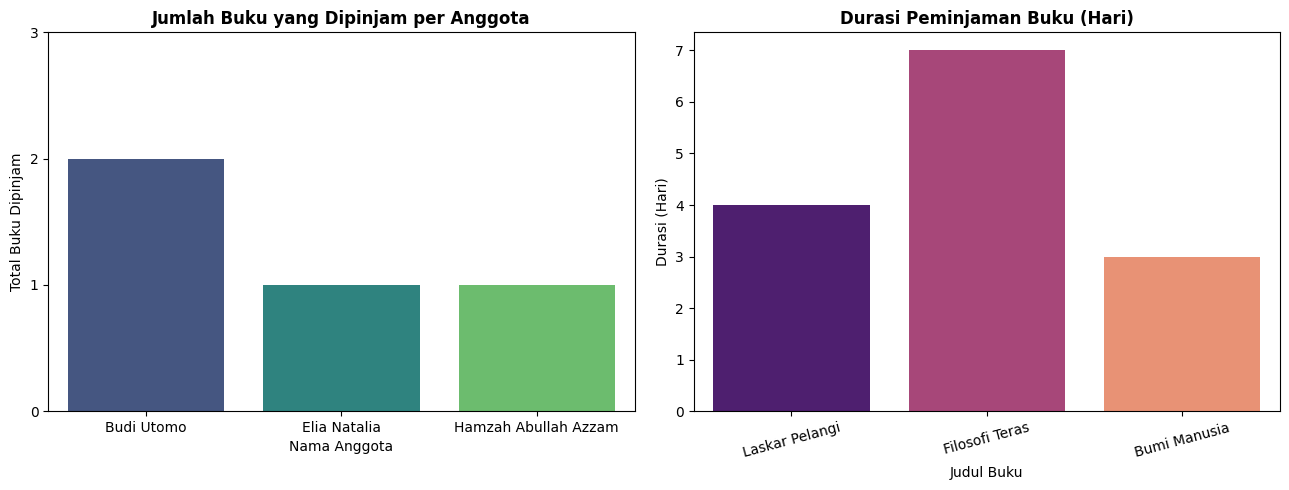

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# 2a. Membuat DataFrame pandas dari hasil query SQL (mengambil dari query 1c dan 1d)
df_peminjaman = pd.read_sql_query(query_1c, conn)
df_total_pinjam = pd.read_sql_query(query_1d, conn)

# 2b. Eksplorasi data sederhana: menghitung durasi peminjaman dalam hari
df_peminjaman['tgl_pinjam'] = pd.to_datetime(df_peminjaman['tgl_pinjam'])
df_peminjaman['tgl_kembali'] = pd.to_datetime(df_peminjaman['tgl_kembali'])

# Hitung selisih hari (yang belum kembali otomatis bernilai NaN)
df_peminjaman['durasi_hari'] = (df_peminjaman['tgl_kembali'] - df_peminjaman['tgl_pinjam']).dt.days
df_peminjaman['status'] = df_peminjaman['tgl_kembali'].apply(lambda x: 'Belum Kembali' if pd.isna(x) else 'Sudah Kembali')

print("--- 2b. Hasil Eksplorasi Data Peminjaman ---")
display(df_peminjaman[['nama_anggota', 'judul_buku', 'durasi_hari', 'status']])
print(f"\nRata-rata durasi peminjaman (buku yang sudah kembali): {df_peminjaman['durasi_hari'].mean():.1f} hari")

# 2c. Visualisasi data menggunakan Matplotlib dan Seaborn
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Grafik 1: Diagram batang jumlah buku yang dipinjam per anggota
sns.barplot(
    data=df_total_pinjam,
    x='nama_anggota',
    y='total_buku_dipinjam',
    palette='viridis',
    ax=axes[0]
)
axes[0].set_title('Jumlah Buku yang Dipinjam per Anggota', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Nama Anggota')
axes[0].set_ylabel('Total Buku Dipinjam')
axes[0].set_yticks(range(0, int(df_total_pinjam['total_buku_dipinjam'].max()) + 2))

# Grafik 2: Diagram batang durasi peminjaman untuk transaksi yang sudah selesai
df_selesai = df_peminjaman.dropna(subset=['durasi_hari'])
sns.barplot(
    data=df_selesai,
    x='judul_buku',
    y='durasi_hari',
    palette='magma',
    ax=axes[1]
)
axes[1].set_title('Durasi Peminjaman Buku (Hari)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Judul Buku')
axes[1].set_ylabel('Durasi (Hari)')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

# Menutup koneksi database setelah selesai
conn.close()